In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("=" * 50)
print("SUCCESS: Dataset loaded!")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
print("=" * 50)
df.head(3)

SUCCESS: Dataset loaded!
Total Rows: 7043, Total Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [3]:
print(df.info())
print("\nMissing values before cleaning:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Missing values in TotalCharges after coercion:")
print(df['TotalCharges'].isnull().sum())

median_val = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_val)

df = df.drop(columns=['customerID'])

print("\nMissing values remaining in TotalCharges:", df['TotalCharges'].isnull().sum())
print("New dataset shape:", df.shape)

Missing values in TotalCharges after coercion:
11

Missing values remaining in TotalCharges: 0
New dataset shape: (7043, 20)


In [5]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("Target variable distribution:")
print(df['Churn'].value_counts(normalize=True))

df_encoded = pd.get_dummies(df, drop_first=True)

print("\nShape after One-Hot Encoding:", df_encoded.shape)
df_encoded.head(3)

Target variable distribution:
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

Shape after One-Hot Encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

df_encoded[numerical_cols] = scaler.fit_transform(df_encoded[numerical_cols])

print("Normalized numerical feature statistics (mean ~ 0, std ~ 1):")
print(df_encoded[numerical_cols].describe().round(2))

Normalized numerical feature statistics (mean ~ 0, std ~ 1):
        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean     -0.00           -0.00         -0.00
std       1.00            1.00          1.00
min      -1.32           -1.55         -1.00
25%      -0.95           -0.97         -0.83
50%      -0.14            0.19         -0.39
75%       0.92            0.83          0.66
max       1.61            1.79          2.83


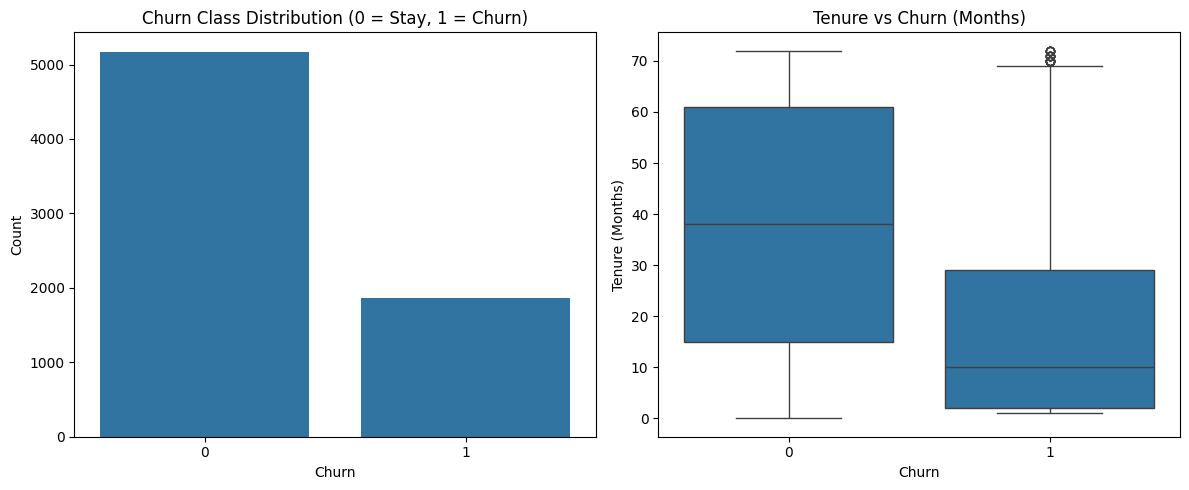

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(x='Churn', data=df)
plt.title('Churn Class Distribution (0 = Stay, 1 = Churn)')
plt.xlabel('Churn')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title('Tenure vs Churn (Months)')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')

plt.tight_layout()
plt.show()

In [8]:
output_file = "cleaned_telco_churn.csv"
df_encoded.to_csv(output_file, index=False)

print("Preprocessing complete!")
print(f"Cleaned dataset saved as '{output_file}' with shape {df_encoded.shape}")

Preprocessing complete!
Cleaned dataset saved as 'cleaned_telco_churn.csv' with shape (7043, 31)


In [9]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Distribution:\n", y_train.value_counts(normalize=True))
print("Testing Target Distribution:\n", y_test.value_counts(normalize=True))

Training Features Shape: (5634, 30)
Testing Features Shape: (1409, 30)
Training Target Distribution:
 Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64
Testing Target Distribution:
 Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"Model trained successfully: {name}")

Model trained successfully: Logistic Regression
Model trained successfully: Decision Tree
Model trained successfully: Random Forest
Model trained successfully: K-Nearest Neighbors


In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_prob)
    
    results.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc, 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False)
print("SUPERVISED MODEL PERFORMANCE COMPARISON:")
print(comparison_df.to_string(index=False))

SUPERVISED MODEL PERFORMANCE COMPARISON:
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8048     0.6552  0.5588    0.6032   0.8420
      Random Forest    0.8105     0.6890  0.5214    0.5936   0.8432
      Decision Tree    0.7942     0.6296  0.5455    0.5845   0.8284
K-Nearest Neighbors    0.7708     0.5706  0.5508    0.5605   0.8031


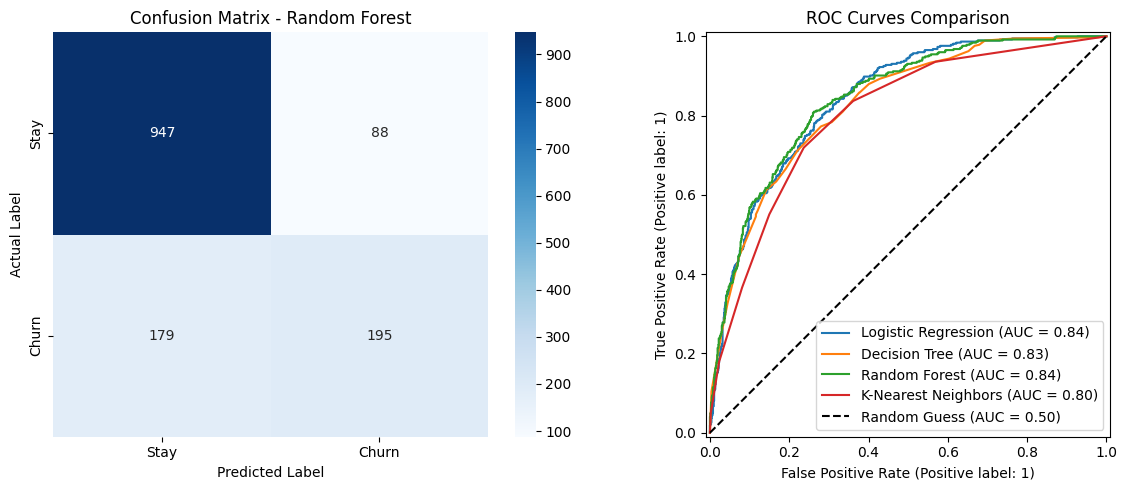

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, RocCurveDisplay

best_model = trained_models["Random Forest"]
y_pred_best = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stay', 'Churn'],
            yticklabels=['Stay', 'Churn'])
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

ax = plt.subplot(1, 2, 2)
for name, model in trained_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
plt.title('ROC Curves Comparison')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
pca_features = pca.fit_transform(X)

pca_df = pd.DataFrame(data=pca_features, columns=['PC1', 'PC2'])
print("PCA Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Variance Retained:", round(sum(pca.explained_variance_ratio_) * 100, 2), "%")
print("PCA features shape:", pca_df.shape)
pca_df.head(3)

PCA Explained Variance Ratio: [0.392108   0.18683002]
Total Variance Retained: 57.89 %
PCA features shape: (7043, 2)


,PC1,PC2
0,-1.453178,-1.252021
1,-0.279358,-0.096339
2,-1.094977,-1.308254


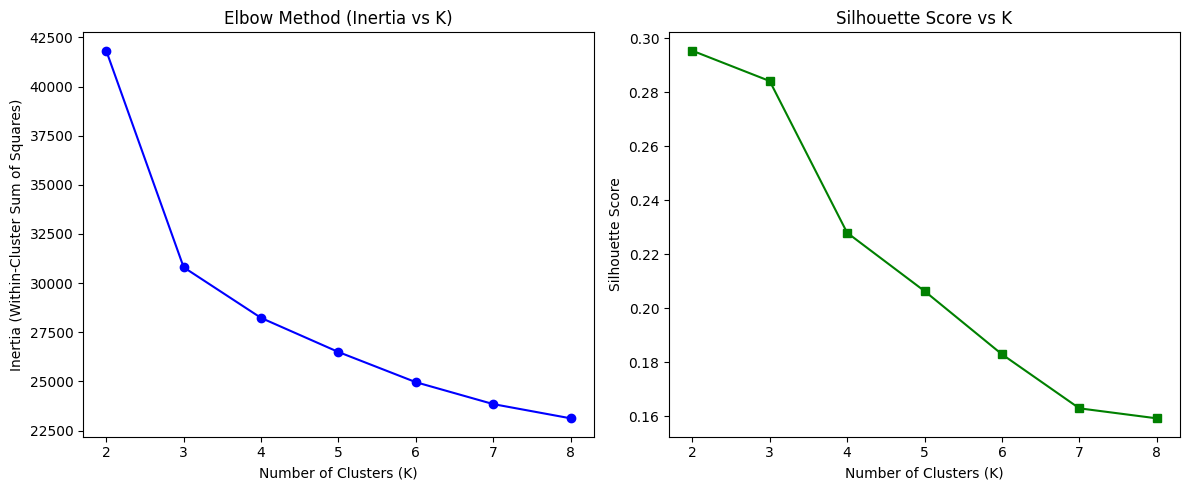

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_list = []
silhouette_list = []
k_range = range(2, 9)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia_list.append(kmeans.inertia_)
    silhouette_list.append(silhouette_score(X, kmeans.labels_))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(k_range, inertia_list, marker='o', color='b')
plt.title('Elbow Method (Inertia vs K)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')

plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_list, marker='s', color='g')
plt.title('Silhouette Score vs K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

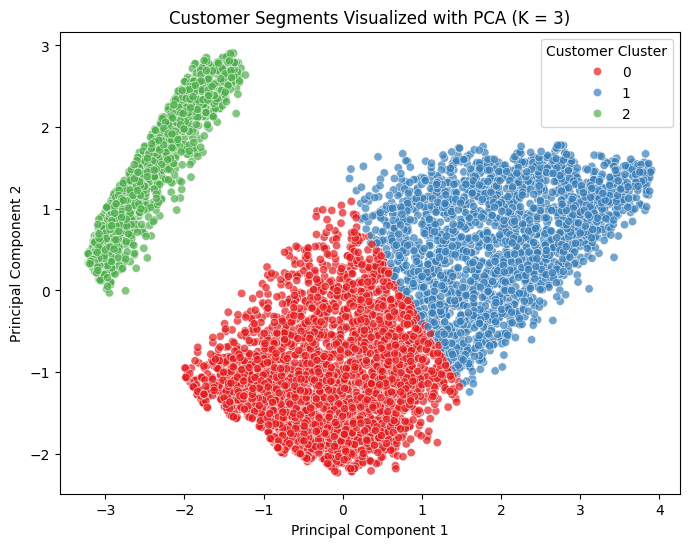

CUSTOMER CLUSTER PROFILES:
         tenure  MonthlyCharges  TotalCharges  Churn_Rate
Cluster                                                  
0         15.56           67.99       1035.47        0.43
1         57.98           89.68       5182.61        0.15
2         30.55           21.08        668.10        0.07


In [16]:
optimal_k = 3
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = final_kmeans.fit_predict(X)

pca_df['Cluster'] = cluster_labels
df['Cluster'] = cluster_labels

plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', palette='Set1', data=pca_df, alpha=0.7)
plt.title(f'Customer Segments Visualized with PCA (K = {optimal_k})')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Customer Cluster')
plt.show()

cluster_summary = df.groupby('Cluster').agg({
    'tenure': 'mean',
    'MonthlyCharges': 'mean',
    'TotalCharges': 'mean',
    'Churn': 'mean'
}).rename(columns={'Churn': 'Churn_Rate'}).round(2)

print("CUSTOMER CLUSTER PROFILES:")
print(cluster_summary)

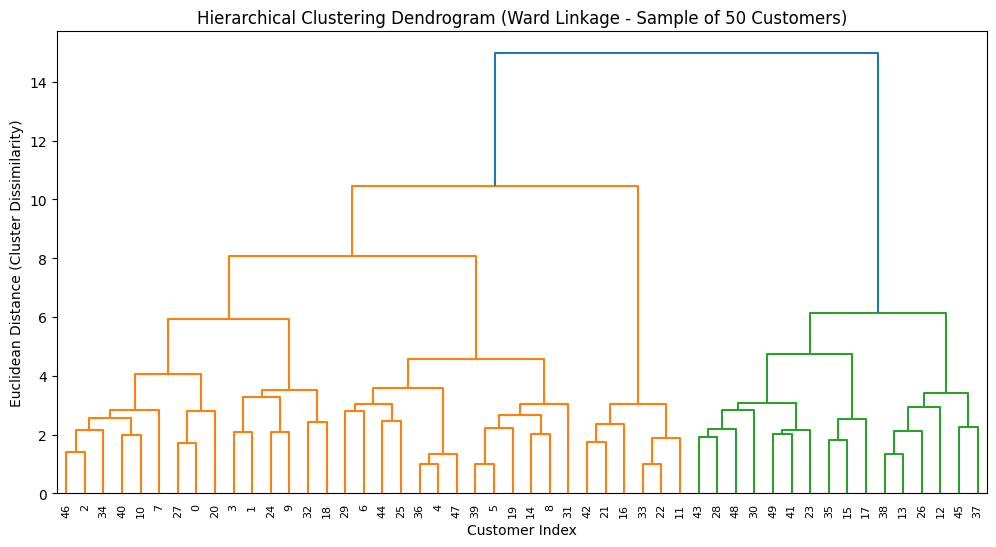

In [17]:
from scipy.cluster.hierarchy import dendrogram, linkage

sample_X = X.iloc[:50]
linked = linkage(sample_X, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(linked,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=True)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage - Sample of 50 Customers)')
plt.xlabel('Customer Index')
plt.ylabel('Euclidean Distance (Cluster Dissimilarity)')
plt.show()

In [18]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [6, 10],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced', None]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
print("Optimal Hyperparameters Found:")
print(grid_search.best_params_)
print(f"Best 5-Fold Cross-Validation ROC-AUC: {round(grid_search.best_score_, 4)}")

y_pred_tuned = best_rf.predict(X_test)
y_prob_tuned = best_rf.predict_proba(X_test)[:, 1]

print("\nTUNED RANDOM FOREST TEST METRICS:")
print(f"Accuracy:  {round(accuracy_score(y_test, y_pred_tuned), 4)}")
print(f"Recall:    {round(recall_score(y_test, y_pred_tuned), 4)}")
print(f"Precision: {round(precision_score(y_test, y_pred_tuned), 4)}")
print(f"F1-Score:  {round(f1_score(y_test, y_pred_tuned), 4)}")
print(f"ROC-AUC:   {round(roc_auc_score(y_test, y_prob_tuned), 4)}")

Optimal Hyperparameters Found:
{'class_weight': 'balanced', 'max_depth': 6, 'min_samples_split': 5, 'n_estimators': 200}
Best 5-Fold Cross-Validation ROC-AUC: 0.8455

TUNED RANDOM FOREST TEST METRICS:
Accuracy:  0.7445
Recall:    0.8048
Precision: 0.5119
F1-Score:  0.6258
ROC-AUC:   0.8423
